# Hierarchical Clustering — Step-by-Step Python Notebook
**Datasets:** Seven simple points (to read the dendrogram) and Wine (standard scikit-learn dataset).

**Aim:** Understand the dendrogram, compare linkage methods, cluster the Wine dataset, and describe the clusters. No external files are needed.

## 1. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

## 2. Start with seven points
A small dataset makes it easier to read every leaf and merge. The numbers are one-dimensional coordinates.

In [3]:
points = [[1], [2], [4], [5], [9], [10], [15]]
names = ["A", "B", "C", "D", "E", "F", "G"]

display(pd.DataFrame({"Point": names, "Value": [x[0] for x in points]}))

,Point,Value
0,A,1
1,B,2
2,C,4
3,D,5
4,E,9
5,F,10
6,G,15


## 3. Draw a dendrogram (Single Linkage)
Single linkage uses the shortest distance between a pair of points from different clusters.

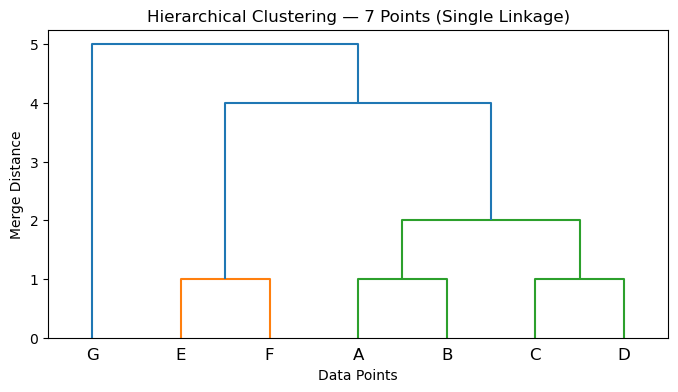

In [4]:
Z_single = linkage(points, method="single")
plt.figure(figsize=(8, 4))
dendrogram(Z_single, labels=names)
plt.title("Hierarchical Clustering — 7 Points (Single Linkage)")
plt.xlabel("Data Points")
plt.ylabel("Merge Distance")
plt.show()

## 4. Compare with Ward linkage
Ward chooses the merge that causes the smallest **increase in within-cluster sum of squares**. In SciPy's dendrogram, Ward's displayed linkage heights use a scaled distance convention, rather than the raw increase in SSE.

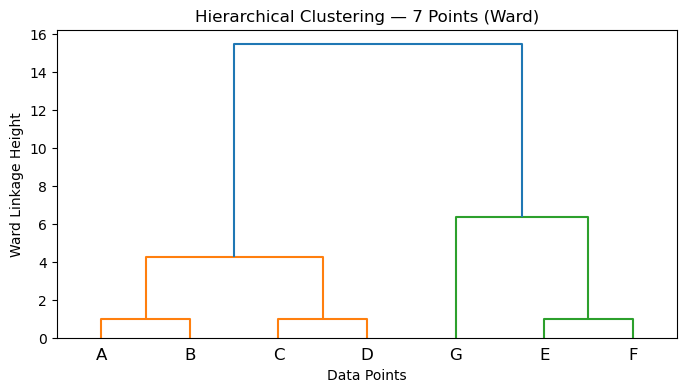

In [5]:
Z_ward = linkage(points, method="ward")
plt.figure(figsize=(8, 4))
dendrogram(Z_ward, labels=names)
plt.title("Hierarchical Clustering — 7 Points (Ward)")
plt.xlabel("Data Points")
plt.ylabel("Ward Linkage Height")
plt.show()

## 5. Load the Wine dataset
The Wine dataset contains 178 samples and 13 numeric features. We scale them because Ward depends on Euclidean distances.

In [6]:
wine = load_wine(as_frame=True)
X = wine.data
X_scaled = StandardScaler().fit_transform(X)
print("Wine data shape:", X.shape)

Wine data shape: (178, 13)


## 6. Draw the Wine dendrogram
The last 15 merged groups are displayed to keep the chart readable. A horizontal cut at a chosen height determines the number of clusters.

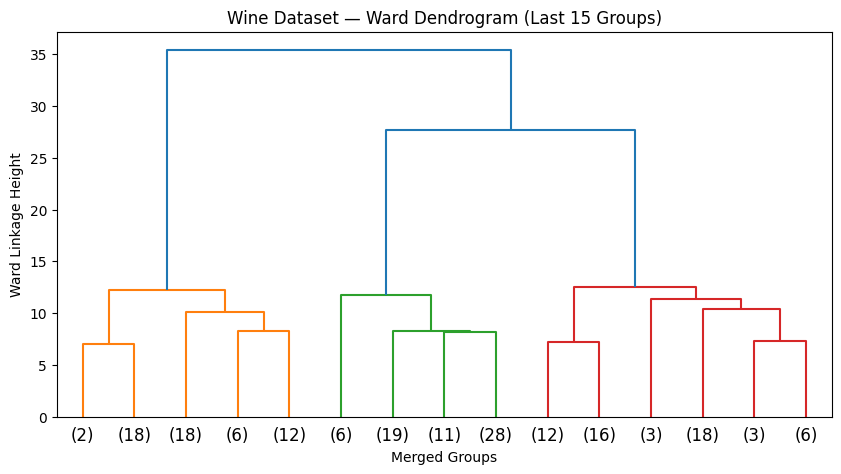

In [6]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=15)
plt.title("Wine Dataset — Ward Dendrogram (Last 15 Groups)")
plt.xlabel("Merged Groups")
plt.ylabel("Ward Linkage Height")
plt.show()

## 7. Train Hierarchical Clustering (`n_clusters=3`)
For classroom comparison with Wine's known three classes, we set 3 clusters. In a real unsupervised project, use the dendrogram and domain context to help choose a meaningful number.

In [7]:
model = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels = model.fit_predict(X_scaled)
print("Cluster sizes:")
print(pd.Series(labels).value_counts().sort_index())

Cluster sizes:
0    58
1    56
2    64
Name: count, dtype: int64


## 8. Visualize clusters (PCA View)
Hierarchical clustering uses all 13 scaled features; PCA is only for a 2D plot.

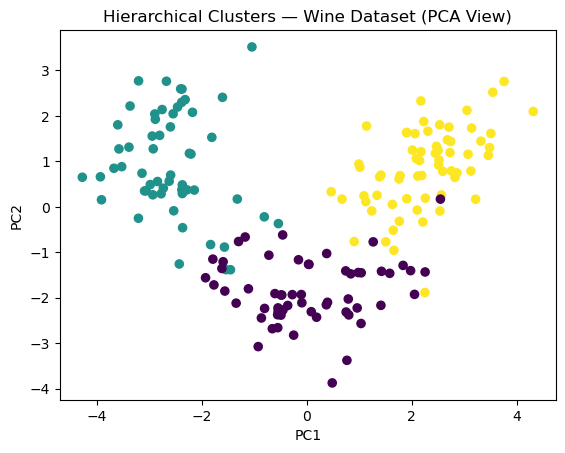

In [8]:
X_pca = PCA(n_components=2).fit_transform(X_scaled)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis", s=35)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Hierarchical Clusters — Wine Dataset (PCA View)")
plt.show()

## 9. Understand the clusters (profiling)
Group the **original, unscaled feature values** by cluster to identify how clusters differ.

In [9]:
profile = X.copy()
profile["Cluster"] = labels

display(profile.groupby("Cluster").mean().round(2))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Cluster,,,,,,,,,,,,,
0,12.20,1.94,2.22,20.21,92.55,2.26,2.09,0.36,1.69,2.90,1.06,2.86,501.43
1,13.06,3.17,2.41,21.00,99.86,1.69,0.85,0.45,1.13,6.85,0.72,1.73,624.95
2,13.67,1.97,2.46,17.53,106.16,2.85,3.01,0.29,1.91,5.45,1.07,3.16,1076.05
